# The object pipeline, end to end

This takes one recording and produces the two things the project was asked for: the path an
object travels through the room and the 3D points belonging to it.

Everything that ties it to a particular recording sits in one cell at the top, so changing
the recording is an edit there rather than a hunt through the code. `tools/object_runs.csv`
holds those choices for all twelve recordings and `tools/run_all_objects.py` drives the set.

## The chain

1. Pick a point on the object in one frame. A person does this, since no automatic rule has
   been made to work.
2. SAM 2 propagates that point into a mask on every later frame.
3. The two forward cameras give a depth map per frame, since Gen 2 has no depth sensor.
4. Unproject the depth into 3D points, keep the ones landing inside the mask.
5. Chain the device pose to put the whole thing into room coordinates.

In [1]:
from pathlib import Path

# Where does everything live ? We work the repository out from the notebook's own location,
# so you can rename or move the repository and nothing below breaks.
NOTEBOOKS = Path.cwd()
REPO      = NOTEBOOKS.parent

RECORDINGS = REPO / "recordings"
MODELS     = REPO / "models"
CACHE      = REPO / "cache"
OUTPUTS    = REPO / "outputs"
for d in (CACHE, OUTPUTS):
    d.mkdir(parents=True, exist_ok=True)

assert RECORDINGS.is_dir(), f"no recordings folder at {RECORDINGS}"
assert MODELS.is_dir(), f"no models folder at {MODELS}, the SAM weights live there"
print("repo:", REPO)

repo: /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics


## Everything that pins this to one recording

These six values are the whole configuration. `PROMPT` is the one that cannot be derived. It is a pixel coordinate on the object,
read off a gridded plot of the frame at `START_S`. The cell after next shows the frame with
the point marked, so you can see it is on the spoon rather than taking it on trust.

In [2]:
# The recording and the window within it.
RECORDING  = "pick_02"
# Names the outputs. One recording can hold more than one object worth tracking,
# for eg. the spoon being moved and the bowl it is moved into, so the label rather
# than the recording is what keeps their results apart.
LABEL      = "pick_02"
START_S    = 5.13         # the spoon is clear of the blue bowl, mid carry
DURATION_S = 4.0         # 120 frames at 30 fps

# A pixel on the object in the frame at START_S, read off the gridded plot below.
PROMPT = [1185, 762]

# Depth beyond this is not worth keeping from a 14 cm baseline, since the error grows with
# the square of distance and reaches 11 cm at two metres.
MAX_DEPTH = 2.0

# How far from the last sighting we bother looking. The object cannot teleport in a
# thirtieth of a second and testing every one of eighty thousand points per frame against
# the mask would dominate the runtime.
SEARCH_RADIUS = 0.25

N_FRAMES = int(DURATION_S * 30)
# The cache tag carries the window, so changing START_S does not silently reuse the wrong
# frames. The output stem does not, because there is one current result per recording and
# a filename carrying a stale window number is worse than a file that gets overwritten.
TAG = f"{LABEL}_{int(START_S * 10)}"
STEM = f"object_{LABEL}"
print(f"{RECORDING}, {START_S} to {START_S + DURATION_S} s, {N_FRAMES} frames")
print(f"cache tag {TAG}, outputs named {STEM}_*")

pick_02, 5.13 to 9.129999999999999 s, 120 frames
cache tag pick_02_51, outputs named object_pick_02_*


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from projectaria_tools.core import data_provider, calibration
from projectaria_tools.core.sensor_data import (
    TimeDomain, TimeQueryOptions, VioStatus, TrackingQuality)
from projectaria_tools.core.sophus import SO3

vrs_path = sorted(RECORDINGS.glob(f"{RECORDING}_*.vrs"))[0]
provider = data_provider.create_vrs_data_provider(str(vrs_path))

rgb_id   = provider.get_stream_id_from_label("camera-rgb")
left_id  = provider.get_stream_id_from_label("slam-front-left")
right_id = provider.get_stream_id_from_label("slam-front-right")
vio_id   = provider.get_stream_id_from_label("vio")
first_ns = provider.get_first_time_ns(rgb_id, TimeDomain.DEVICE_TIME)

print(f"{vrs_path.name}")
print(f"colour frames {provider.get_num_data(rgb_id)}, vio samples {provider.get_num_data(vio_id)}")

pick_02_20261008_150327.vrs
colour frames 343, vio samples 114


[ProgressLogger][INFO]: 2026-10-22 22:33:20: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pick_02_20261008_150327.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 158344112
[VRSIndexRecord][WARNING]: 1 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pick_02_20261008_150327.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INFO]

## Checking the prompt point

A coordinate typed into a cell is worth nothing unless you can see where it lands. So we
draw the frame with the point on it and run SAM once, then look at the outline.

mask at the prompt: 24,455 pixels


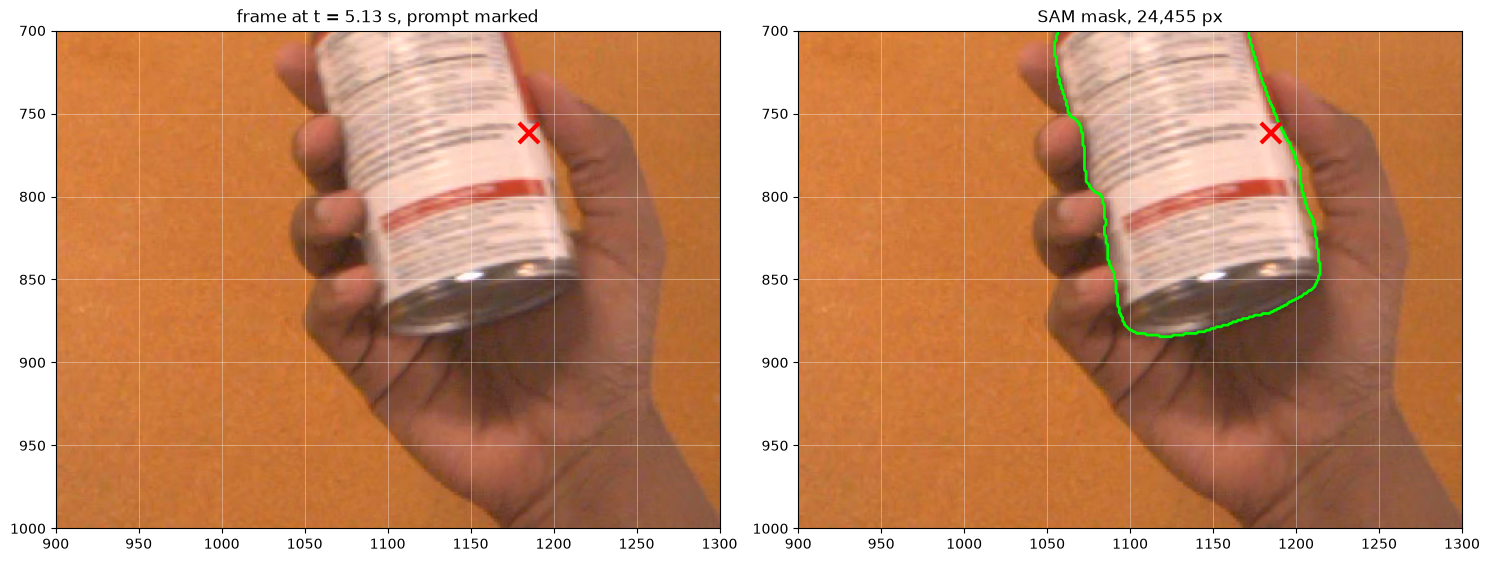

In [4]:
from ultralytics import SAM

t_start_ns = first_ns + int(START_S * 1e9)
frame0 = provider.get_image_data_by_time_ns(
    rgb_id, t_start_ns, TimeDomain.DEVICE_TIME, TimeQueryOptions.CLOSEST)[0].to_numpy_array()

sam = SAM(str(MODELS / "sam2_b.pt"))
mask0 = sam(frame0, points=[PROMPT], labels=[1], verbose=False)[0].masks.data[0].cpu().numpy() > 0.5
print(f"mask at the prompt: {int(mask0.sum()):,} pixels")

# A crop, because the spoon is a few hundred pixels inside a two million pixel frame and
# would be invisible otherwise. Real coordinates stay on the axes so the number above can
# be checked against the picture.
X0, X1, Y0, Y1 = 900, 1300, 700, 1000
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, overlay in zip(axes, (False, True)):
    ax.imshow(frame0[Y0:Y1, X0:X1], extent=[X0, X1, Y1, Y0])
    if overlay:
        ax.contour(np.arange(X0, X1), np.arange(Y0, Y1), mask0[Y0:Y1, X0:X1],
                   levels=[0.5], colors="lime", linewidths=2)
        ax.set_title(f"SAM mask, {int(mask0.sum()):,} px", fontsize=12)
    else:
        ax.set_title(f"frame at t = {START_S} s, prompt marked", fontsize=12)
    ax.plot(*PROMPT, "x", color="red", markersize=14, markeredgewidth=3)
    ax.grid(color="white", alpha=0.35, linewidth=0.7)
plt.tight_layout()
plt.show()

## Exporting the window and encoding it

SAM 2's video predictor counts frames through its source and that counter only exists for
a real video file rather than a folder of images. So the window goes out as individual
frames and then gets encoded into an mp4.

Both steps are skipped when their output already exists, because neither is interesting and
both are slow.

In [5]:
import cv2
from PIL import Image

fwd = CACHE / f"frames_{TAG}"
fwd.mkdir(parents=True, exist_ok=True)

if len(sorted(fwd.glob("*.jpg"))) >= N_FRAMES:
    print(f"frames already exported to {fwd.name}")
else:
    n, t = 0, START_S
    while n < N_FRAMES:
        d, _ = provider.get_image_data_by_time_ns(
            rgb_id, first_ns + int(t * 1e9), TimeDomain.DEVICE_TIME, TimeQueryOptions.CLOSEST)
        if d.is_valid():
            # Zero padded names, because ordering is what tells the propagation which frame
            # follows which.
            Image.fromarray(d.to_numpy_array()).save(fwd / f"{n:05d}.jpg", quality=92)
            n += 1
        t += 1.0 / 30.0
    print(f"exported {n} frames")

video_path = CACHE / f"{TAG}.mp4"
if video_path.exists():
    print(f"video already encoded at {video_path.name}")
else:
    sample = cv2.imread(str(fwd / "00000.jpg"))
    h, w = sample.shape[:2]
    writer = cv2.VideoWriter(str(video_path), cv2.VideoWriter_fourcc(*"mp4v"), 30.0, (w, h))
    for f in sorted(fwd.glob("*.jpg")):
        # imread already returns BGR, which is what the writer wants, so nothing is swapped.
        writer.write(cv2.imread(str(f)))
    writer.release()
    print(f"encoded {video_path.name}")

frames already exported to frames_pick_02_51
video already encoded at pick_02_51.mp4


## Tracking the object through the window

This is the expensive cell. SAM runs its image encoder on every frame and carries a memory
of the object between them, which takes several minutes on a CPU. The masks are cached as
packed bits, so a rerun costs nothing. Set `FORCE_PROPAGATION` when the prompt or the window
changes.

In [6]:
FORCE_PROPAGATION = False

mask_cache = CACHE / f"masks_{TAG}.npz"
H, W = frame0.shape[:2]

if mask_cache.exists() and not FORCE_PROPAGATION:
    z = np.load(mask_cache)
    # Stored as packed bits, since a full resolution boolean mask per frame would otherwise
    # run to hundreds of megabytes.
    masks = [np.unpackbits(z[k])[:H * W].reshape(H, W).astype(bool) for k in sorted(z.files)]
    print(f"loaded {len(masks)} cached masks, set FORCE_PROPAGATION to run it again")
else:
    from ultralytics.models.sam import SAM2VideoPredictor
    overrides = dict(conf=0.25, task="segment", mode="predict", imgsz=1024,
                     model=str(MODELS / "sam2_b.pt"), save=False, verbose=False)
    # A fresh predictor, because the class holds inference state across frames and we do not
    # want a previous run bleeding into this one.
    predictor = SAM2VideoPredictor(overrides=overrides)
    results = predictor(source=str(video_path), points=[PROMPT], labels=[1])
    masks = []
    for r in results:
        # A frame where SAM found nothing gets an empty mask rather than being skipped, so
        # the list stays index aligned with the frames.
        masks.append(np.zeros((H, W), bool) if (r.masks is None or len(r.masks) == 0)
                     else r.masks.data[0].cpu().numpy() > 0.5)
    np.savez_compressed(mask_cache, **{f"m{i:04d}": np.packbits(m) for i, m in enumerate(masks)})
    print(f"propagated {len(masks)} frames and cached them")

sizes = np.array([int(m.sum()) for m in masks])
print(f"mask size: min {sizes.min():,}  median {int(np.median(sizes)):,}  max {sizes.max():,}")

loaded 120 cached masks, set FORCE_PROPAGATION to run it again


mask size: min 8,619  median 10,275  max 25,456


## Does the mask stay on the object ?

SAM's own confidence stays at 1.00 even while the mask drifts onto a different object, so
the model cannot report its own failure. Mask area can, at least crudely. A mask that
suddenly multiplies in size has jumped to something bigger and one that collapses has
fallen onto a highlight.

**A flag is a request to look rather than a verdict.** Apparent area depends on distance as
much as on identity, so an object carried away from the camera shrinks without anything
going wrong. A 2.5 times change in area is only a 1.6 times change in distance.

**No flag is not a guarantee either.** A mask that moves to a nearby object of roughly
twice the size grows by less than the threshold and passes. The baseline comes from the
opening frames, so a click that was wrong from the first frame sets the baseline to the
wrong object and nothing is ever flagged.

So this catches the loud failures and cannot be the only check. Run
`tools/check_tracking.py <recording>` and look at the frames before trusting a run.

baseline from the first 10 frames: 23,188 px
frames whose mask area looks wrong: 71 of 120
  first at frame 49 = t 6.8 s
  if the tracking did fail there, frames 0 to 48 are the usable stretch
  check it first: python3 tools/check_tracking.py pick_02


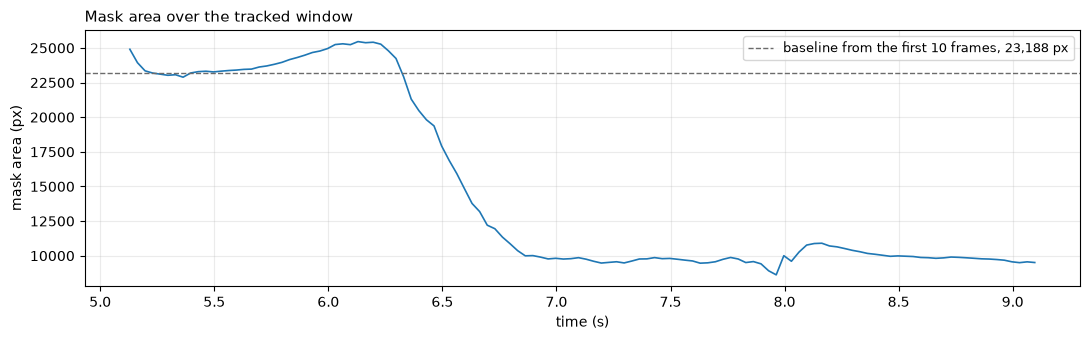

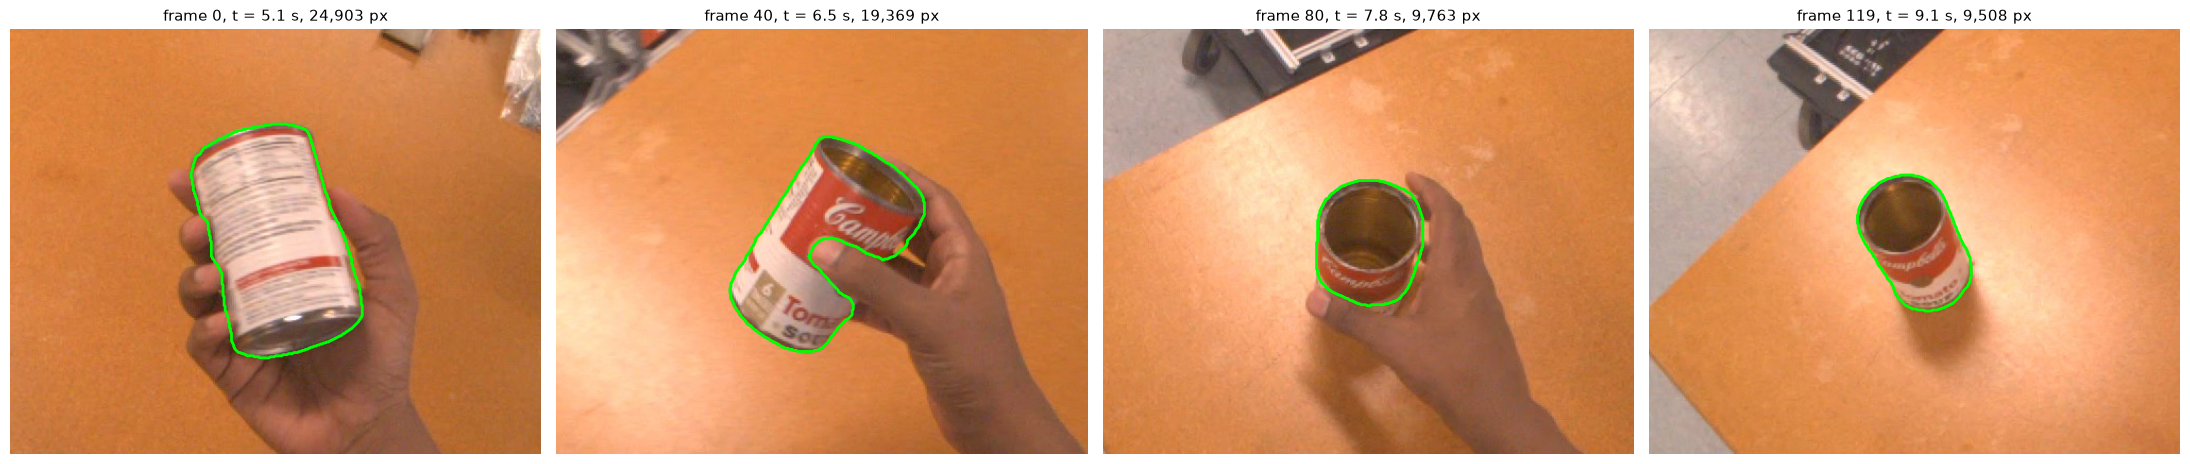

In [7]:
# The prompt was checked by eye on the opening frames, so those are the only frames we have
# any right to trust as a baseline. Why not the median of the whole run ? Because that
# fails in the exact case this exists to catch. When tracking decays steadily the median
# sinks along with it, so nothing ever looks unusual and a mask can fall to a seventh of
# its size with barely a frame flagged.
baseline = np.median(sizes[:10])

# A mask that has halved or more than doubled, against the frames we trust is no longer
# describing the same object.
suspect = np.nonzero((sizes > 2.5 * baseline) | (sizes < 0.5 * baseline))[0]
print(f"baseline from the first 10 frames: {baseline:,.0f} px")
print(f"frames whose mask area looks wrong: {len(suspect)} of {len(sizes)}")
if len(suspect):
    print(f"  first at frame {suspect[0]} = t {START_S + suspect[0]/30:.1f} s")
    # Losing the object part way through is the usual reason for a flag, so point at where
    # the run would stop being trustworthy if that is what happened here. We say "look"
    # rather than "stop", because the other reason for a flag is an object simply being
    # carried further from the camera, which is not a failure at all.
    run = suspect[0]
    print(f"  if the tracking did fail there, frames 0 to {run-1} are the usable stretch")
    print(f"  check it first: python3 tools/check_tracking.py {RECORDING}")
else:
    print("  the mask held its size across the whole window")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(np.arange(len(sizes)) / 30 + START_S, sizes, lw=1.2, color="#1f77b4")
ax.axhline(baseline, color="#6b6b6b", ls="--", lw=1,
           label=f"baseline from the first 10 frames, {baseline:,.0f} px")
ax.set_xlabel("time (s)"); ax.set_ylabel("mask area (px)")
ax.set_title("Mask area over the tracked window", loc="left", fontsize=11)
ax.legend(fontsize=9); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

# A look at four frames spread across the window, which is the check the number cannot do.
idx = [0, len(masks)//3, 2*len(masks)//3, len(masks)-1]
fig, axes = plt.subplots(1, 4, figsize=(22, 6))
for ax, i in zip(axes, idx):
    img = np.array(Image.open(fwd / f"{i:05d}.jpg"))
    ys, xs = np.nonzero(masks[i])
    if len(xs):
        cx, cy = int(xs.mean()), int(ys.mean())
    else:
        cx, cy = W // 2, H // 2
    x0, x1 = max(0, cx-250), min(W, cx+250)
    y0, y1 = max(0, cy-200), min(H, cy+200)
    ax.imshow(img[y0:y1, x0:x1], extent=[x0, x1, y1, y0])
    if len(xs):
        ax.contour(np.arange(x0, x1), np.arange(y0, y1), masks[i][y0:y1, x0:x1],
                   levels=[0.5], colors="lime", linewidths=2)
    ax.set_title(f"frame {i}, t = {START_S + i/30:.1f} s, {sizes[i]:,} px", fontsize=11)
    ax.axis("off")
plt.tight_layout(); plt.show()

## Stereo depth, built from the two forward cameras

Gen 2 has no depth sensor, so depth comes from the forward pair used as a stereo rig. They
are not a usable pair as they come, because they sit on a curved frame and point outward,
so we construct the rectified geometry from the baseline and check it rather than trusting
it. The checks below are the ones that matter: both frames orthonormal and the baseline
landing on the x axis once rectified.

In [8]:
dev_cal  = provider.get_device_calibration()
left_c   = dev_cal.get_camera_calib("slam-front-left")
right_c  = dev_cal.get_camera_calib("slam-front-right")
rgb_c    = dev_cal.get_camera_calib("camera-rgb")

T_l, T_r = left_c.get_transform_device_camera(), right_c.get_transform_device_camera()
R_l = np.asarray(T_l.rotation().to_matrix()); t_l = np.asarray(T_l.translation()).reshape(-1)
R_r = np.asarray(T_r.rotation().to_matrix()); t_r = np.asarray(T_r.translation()).reshape(-1)

# The right camera expressed in left camera coordinates. The left camera is also the device
# origin, which is why everything downstream lands in the device frame without extra work.
R_LR = R_l.T @ R_r
t_LR = R_l.T @ (t_r - t_l)
baseline = np.linalg.norm(t_LR)

angle = np.degrees(np.arccos(np.clip((np.trace(R_LR) - 1) / 2, -1, 1)))
print(f"baseline {baseline*100:.2f} cm, optical axes {angle:.2f} degrees apart")
print(f"off axis: y {t_LR[1]*100:.2f} cm, z {t_LR[2]*100:.2f} cm")

# A rectified pair shares one orientation and has its x axis along the baseline, so we build
# that frame directly from the baseline.
new_x = t_LR / baseline
new_y = np.cross(np.array([0.0, 0.0, 1.0]), new_x); new_y /= np.linalg.norm(new_y)
new_z = np.cross(new_x, new_y)
R_rect_l = np.vstack([new_x, new_y, new_z])
R_rect_r = R_rect_l @ R_LR

print(f"\northonormality error: left {np.abs(R_rect_l @ R_rect_l.T - np.eye(3)).max():.1e}, "
      f"right {np.abs(R_rect_r @ R_rect_r.T - np.eye(3)).max():.1e}")
print(f"determinants: {np.linalg.det(R_rect_l):.6f}, {np.linalg.det(R_rect_r):.6f}")
# If the baseline does not land on x then rows will not correspond and every disparity we
# measure afterwards is meaningless, so this is the check that matters most.
print(f"baseline off axis residual after rectification: "
      f"{np.abs((R_rect_l @ t_LR)[1:]).max():.2e} m")

# The warp wants the rotation the other way round, from rectified back into each camera.
so3_l, so3_r = SO3.from_matrix(R_rect_l.T), SO3.from_matrix(R_rect_r.T)

RECT_FOCAL = float(left_c.get_focal_lengths()[0]); RECT_SIZE = 512
rect_cal = calibration.get_linear_camera_calibration(RECT_SIZE, RECT_SIZE, RECT_FOCAL, "rect")
cx, cy = [float(v) for v in rect_cal.get_principal_point()]

BLOCK = 5
stereo = cv2.StereoSGBM_create(
    minDisparity=0, numDisparities=128, blockSize=BLOCK,
    # These penalise disparity changing between neighbours, gently for small steps and hard
    # for large ones, which keeps surfaces smooth without flattening real depth edges.
    P1=8 * BLOCK ** 2, P2=32 * BLOCK ** 2, disp12MaxDiff=1, uniquenessRatio=10,
    speckleWindowSize=100, speckleRange=32, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)

T_rgb = rgb_c.get_transform_device_camera()
R_rgb = np.asarray(T_rgb.rotation().to_matrix())
t_rgb = np.asarray(T_rgb.translation()).reshape(-1)
print(f"\nrectified camera {RECT_SIZE}x{RECT_SIZE}, focal {RECT_FOCAL:.1f}, "
      f"field of view {2*np.degrees(np.arctan(RECT_SIZE/2/RECT_FOCAL)):.1f} degrees")

baseline 14.23 cm, optical axes 40.05 degrees apart
off axis: y 1.95 cm, z -4.57 cm

orthonormality error: left 2.2e-16, right 5.9e-17
determinants: 1.000000, 1.000000
baseline off axis residual after rectification: 6.94e-18 m

rectified camera 512x512, focal 246.7, field of view 92.1 degrees


## Checking the depth against the device

Our depth could be wrong by a scale factor or an offset and still look sensible. The glasses
report the wrist and the palm in 3D, worked out on their own chip, so projecting those known
points into our rectified image and reading our own depth at the same pixels is an honest
comparison that our code plays no part in.

In [9]:
hand_id = provider.get_stream_id_from_label("handtracking")
hand = provider.get_interpolated_hand_pose_data(hand_id, t_start_ns, TimeDomain.DEVICE_TIME)

ld = provider.get_image_data_by_time_ns(left_id,  t_start_ns, TimeDomain.DEVICE_TIME, TimeQueryOptions.CLOSEST)[0]
rd = provider.get_image_data_by_time_ns(right_id, t_start_ns, TimeDomain.DEVICE_TIME, TimeQueryOptions.CLOSEST)[0]
lr = calibration.distort_by_calibration_and_apply_rotation(ld.to_numpy_array(), rect_cal, left_c, so3_l)
rr = calibration.distort_by_calibration_and_apply_rotation(rd.to_numpy_array(), rect_cal, right_c, so3_r)

# SGBM returns fixed point with four fractional bits, so we scale to get real pixels.
disparity = stereo.compute(lr, rr).astype(np.float32) / 16.0
valid = disparity > 0
depth = np.full_like(disparity, np.nan)
depth[valid] = RECT_FOCAL * baseline / disparity[valid]
clean = valid & (depth < MAX_DEPTH)
print(f"pixels with a disparity: {valid.mean()*100:.1f}%, within {MAX_DEPTH} m: {clean.mean()*100:.1f}%")
print()

def check(name, p_device):
    """Project a point the device reported and compare its depth with ours."""
    p = np.asarray(p_device).reshape(-1)[:3]
    p_rect = R_rect_l @ (R_l.T @ (p - t_l))
    if p_rect[2] <= 0:
        print(f"  {name}: behind the camera"); return
    px = rect_cal.project(p_rect)
    if px is None:
        print(f"  {name}: outside the rectified image"); return
    u, v = int(round(float(px[0]))), int(round(float(px[1])))
    if not (0 <= u < RECT_SIZE and 0 <= v < RECT_SIZE):
        print(f"  {name}: projects off the image"); return
    # A small window rather than one pixel, because a single pixel may be one of the two
    # thirds that never found a match.
    win = depth[max(0, v-5):v+6, max(0, u-5):u+6]
    win = win[np.isfinite(win) & (win < MAX_DEPTH)]
    if win.size == 0:
        print(f"  {name}: truth {p_rect[2]:.3f} m, no stereo depth nearby"); return
    m = float(np.median(win))
    print(f"  {name}: truth {p_rect[2]:.3f} m, stereo {m:.3f} m, error {m - p_rect[2]:+.3f} m")

if hand is not None:
    for side, lab in ((hand.left_hand, "left"), (hand.right_hand, "right")):
        if side is None:
            print(f"  {lab} hand not tracked here"); continue
        check(f"{lab} wrist", side.get_wrist_position_device())
        check(f"{lab} palm ", side.get_palm_position_device())

pixels with a disparity: 36.2%, within 2.0 m: 32.7%

  left wrist: truth 0.487 m, stereo 0.495 m, error +0.008 m
  left palm : truth 0.520 m, stereo 0.530 m, error +0.010 m
  right wrist: truth 0.432 m, stereo 0.464 m, error +0.032 m
  right palm : truth 0.444 m, stereo 0.428 m, error -0.016 m


## The loop

For each frame: rectify both views, compute disparity, turn it into depth, unproject into 3D
points in the device frame, project those into the RGB camera and keep the ones landing
inside that frame's mask.

In [10]:
vio_t, vio_M = [], []
for i in range(provider.get_num_data(vio_id)):
    v = provider.get_vio_data_by_index(vio_id, i)
    # Both quality flags have to pass, since one bad pose would fling the object across the
    # room and nothing downstream would notice.
    if v.status != VioStatus.VALID or v.pose_quality != TrackingQuality.GOOD:
        continue
    vio_t.append(v.capture_timestamp_ns)
    vio_M.append(np.asarray((v.transform_odometry_bodyimu @ v.transform_bodyimu_device)
                            .to_matrix()).reshape(4, 4))
vio_t = np.array(vio_t, dtype=np.int64); vio_M = np.stack(vio_M)
print(f"usable poses {len(vio_t)} of {provider.get_num_data(vio_id)}")

traj, clouds, last_centre = [], [], None

for k in range(min(N_FRAMES, len(masks))):
    tk = first_ns + int((START_S + k / 30.0) * 1e9)

    ld = provider.get_image_data_by_time_ns(left_id,  tk, TimeDomain.DEVICE_TIME, TimeQueryOptions.CLOSEST)[0]
    rd = provider.get_image_data_by_time_ns(right_id, tk, TimeDomain.DEVICE_TIME, TimeQueryOptions.CLOSEST)[0]
    lr = calibration.distort_by_calibration_and_apply_rotation(ld.to_numpy_array(), rect_cal, left_c, so3_l)
    rr = calibration.distort_by_calibration_and_apply_rotation(rd.to_numpy_array(), rect_cal, right_c, so3_r)

    disp = stereo.compute(lr, rr).astype(np.float32) / 16.0
    ok = disp > 0
    dep = np.full_like(disp, np.nan); dep[ok] = RECT_FOCAL * baseline / disp[ok]
    ok &= dep < MAX_DEPTH

    vi, ui = np.nonzero(ok); zi = dep[vi, ui]
    # The pinhole relation run backwards. A pixel plus a distance places a point in space.
    p_rect = np.stack([(ui - cx) * zi / RECT_FOCAL, (vi - cy) * zi / RECT_FOCAL, zi], axis=1)
    p_dev = (p_rect @ R_rect_l) @ R_l.T + t_l

    idx = (np.arange(len(p_dev)) if last_centre is None
           else np.nonzero(np.linalg.norm(p_dev - last_centre, axis=1) < SEARCH_RADIUS)[0])
    if idx.size == 0:
        traj.append((k, np.nan, np.nan, np.nan, 0)); continue

    # The mask lives in the RGB image while the cloud came from the CV cameras and those
    # sit in different places on the frame, so each point has to be projected into the RGB
    # camera before we can ask which pixel it lands on.
    p_rgbcam = (p_dev[idx] - t_rgb) @ R_rgb
    m_k = masks[k]
    hits = [j for j, q in zip(idx, p_rgbcam)
            if q[2] > 0 and (lambda px: px is not None and 0 <= int(px[0]) < W
                             and 0 <= int(px[1]) < H and m_k[int(px[1]), int(px[0])])(rgb_c.project(q))]

    if not hits:
        traj.append((k, np.nan, np.nan, np.nan, 0)); continue

    pts = p_dev[np.array(hits)]
    # The mask can be right while the depth behind it is wrong. Stereo fails on a
    # transparent surface and along a silhouette edge, where one camera sees past the
    # object and the other does not and it fails by putting points far behind the thing
    # rather than slightly off it. So we take the median point, which a minority of wild
    # values cannot move and keep what sits within the same radius we already trust for
    # tracking. Why not simply take the mean and accept the error ? Because on the first
    # frame there is no previous sighting to fall back on, so a dragged centre there is
    # inherited by every frame after it.
    keep = np.linalg.norm(pts - np.median(pts, axis=0), axis=1) < SEARCH_RADIUS
    if not keep.any():
        traj.append((k, np.nan, np.nan, np.nan, 0)); continue
    pts = pts[keep]
    c = pts.mean(axis=0)
    last_centre = c
    traj.append((k, c[0], c[1], c[2], len(pts)))
    clouds.append((k, pts))

    if k % 20 == 0:
        print(f"  frame {k:>3}: {len(pts):>4} points, centre [{c[0]:.3f}, {c[1]:.3f}, {c[2]:.3f}]")

traj = np.array(traj, dtype=float)
found = ~np.isnan(traj[:, 1])
print(f"\nframes with a 3D position: {int(found.sum())} of {len(traj)}")
print(f"points per frame: min {int(traj[found,4].min())}, "
      f"median {int(np.median(traj[found,4]))}, max {int(traj[found,4].max())}")

usable poses 103 of 114


  frame   0: 2302 points, centre [0.239, -0.099, 0.385]


  frame  20: 2310 points, centre [0.244, -0.110, 0.384]


  frame  40: 1699 points, centre [0.209, -0.146, 0.424]


  frame  60:  919 points, centre [0.270, -0.150, 0.501]


  frame  80:  865 points, centre [0.278, -0.154, 0.525]


  frame 100:  925 points, centre [0.145, -0.190, 0.639]



frames with a 3D position: 120 of 120
points per frame: min 667, median 942, max 2402


## Into room coordinates and out to disk

Everything so far is measured from the wearer's face. Chaining the device pose per frame
converts the path and every cloud into coordinates fixed to the room, which is the only
form a robot can use.

In [11]:
world, world_clouds = [], []
for k, pts in clouds:
    tk = first_ns + int((START_S + k / 30.0) * 1e9)
    # Nearest pose in time. At ten poses a second the worst case is fifty milliseconds,
    # which is a real approximation and a small one.
    M = vio_M[int(np.argmin(np.abs(vio_t - tk)))]
    world.append((k, *(M[:3, :3] @ traj[k, 1:4] + M[:3, 3])))
    world_clouds.append(pts @ M[:3, :3].T + M[:3, 3])
world = np.array(world)

def span(a):
    return np.ptp(a, axis=0) * 100

print(f"device frame span: {span(traj[found][:, 1:4])} cm")
print(f"room frame span:   {span(world[:, 1:4])} cm")
print()

import csv
with open(OUTPUTS / f"{STEM}_trajectory.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["frame", "time_s", "n_points", "device_x", "device_y", "device_z",
                "world_x", "world_y", "world_z"])
    wb = {int(r[0]): r[1:4] for r in world}
    for k in range(len(traj)):
        if np.isnan(traj[k, 1]):
            continue
        wp = wb.get(k)
        w.writerow([k, round(START_S + k / 30.0, 4), int(traj[k, 4])]
                   + [round(v, 5) for v in traj[k, 1:4]]
                   + ([round(v, 5) for v in wp] if wp is not None else ["", "", ""]))

# The npz keeps the per frame structure, which a single merged cloud would throw away.
np.savez_compressed(OUTPUTS / f"{STEM}_clouds.npz",
                    trajectory_device=traj, trajectory_world=world,
                    **{f"frame_{i:03d}": c for i, c in enumerate(world_clouds)})

allp = np.vstack(world_clouds)
# And a PLY, because that opens in CloudCompare or MeshLab without needing any of our code.
with open(OUTPUTS / f"{STEM}_cloud_world.ply", "w") as fh:
    fh.write(f"ply\nformat ascii 1.0\nelement vertex {len(allp)}\n")
    fh.write("property float x\nproperty float y\nproperty float z\nend_header\n")
    for p_ in allp:
        fh.write(f"{p_[0]:.5f} {p_[1]:.5f} {p_[2]:.5f}\n")

print(f"accumulated cloud: {len(allp):,} points")
for f in (f"{STEM}_trajectory.csv", f"{STEM}_clouds.npz", f"{STEM}_cloud_world.ply"):
    print(f"  wrote {f}")

device frame span: [     15.601       9.293      29.369] cm
room frame span:   [     21.459      37.354      19.844] cm



accumulated cloud: 165,830 points
  wrote object_pick_02_trajectory.csv
  wrote object_pick_02_clouds.npz
  wrote object_pick_02_cloud_world.ply


## The two deliverables, drawn

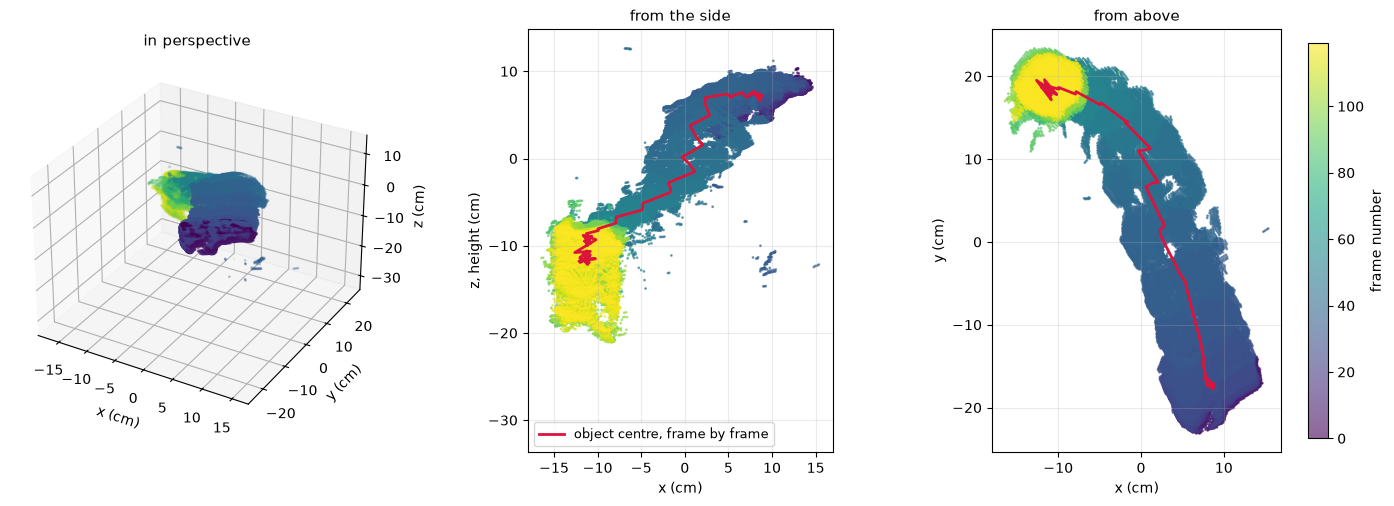

wrote object_pick_02_cloud.png


In [12]:
centre_all = allp.mean(axis=0)
P = (allp - centre_all) * 100
T = (world[:, 1:4] - centre_all) * 100
frame_of = np.concatenate([np.full(len(c), i) for i, c in enumerate(world_clouds)])

fig = plt.figure(figsize=(17, 5.5))

ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=frame_of, cmap="viridis", s=1, alpha=0.6)
ax.plot(T[:, 0], T[:, 1], T[:, 2], color="crimson", lw=2)
ax.set_xlabel("x (cm)"); ax.set_ylabel("y (cm)"); ax.set_zlabel("z (cm)")
ax.set_title("in perspective", fontsize=11)

ax = fig.add_subplot(1, 3, 2)
ax.scatter(P[:, 0], P[:, 2], c=frame_of, cmap="viridis", s=1, alpha=0.6)
ax.plot(T[:, 0], T[:, 2], color="crimson", lw=2, label="object centre, frame by frame")
# Equal aspect or the lift gets stretched to fill the box and stops meaning anything.
ax.set_aspect("equal")
ax.set_xlabel("x (cm)"); ax.set_ylabel("z, height (cm)")
ax.set_title("from the side", fontsize=11); ax.legend(fontsize=9); ax.grid(alpha=0.25)

ax = fig.add_subplot(1, 3, 3)
sc = ax.scatter(P[:, 0], P[:, 1], c=frame_of, cmap="viridis", s=1, alpha=0.6)
ax.plot(T[:, 0], T[:, 1], color="crimson", lw=2)
ax.set_aspect("equal")
ax.set_xlabel("x (cm)"); ax.set_ylabel("y (cm)")
ax.set_title("from above", fontsize=11); ax.grid(alpha=0.25)

cb = fig.colorbar(sc, ax=fig.axes, fraction=0.015, pad=0.02)
cb.set_label("frame number")
# Save before show, because show closes the figure and a savefig after it writes a blank.
fig.savefig(OUTPUTS / f"{STEM}_cloud.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"wrote {STEM}_cloud.png")

## What this produces and what is still manual

Two deliverables, from an October recording, with the configuration in one cell at the top.
Pointing this at `pour_02` or `grip_01` means changing `RECORDING`, `START_S` and `PROMPT`
and running it again.

`PROMPT` is the part that still needs a person. Prompting from the hand was tried on
9 October and it does not transfer: no offset along either the wrist to palm or the palm to
fingertip direction produced an object sized mask on any frame of this recording. The
fingertips are identified as the five landmarks furthest from the wrist, which is a
statement about hand pose rather than anatomy and the set it returns changes within a
single recording. Fixing that properly needs ground truth to measure a rule against, which
is what the HOT3D dataset is for.

Mask area is used above as a crude drift check. It is not a solution. SAM reports a score of
1.00 while tracking the wrong object, so its own confidence cannot be trusted and area only
catches a jump to something much bigger or smaller.